In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
import mlflow
from sklearn.preprocessing import OneHotEncoder, StandardScaler 
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, accuracy_score
from plotnine import *
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import statsmodels.api as sm
from mlflow.data.pandas_dataset import PandasDataset
import uuid
import time

import os

In [2]:
from evidently import ColumnMapping

from evidently.report import Report
from evidently.metrics.base_metric import generate_column_metrics
from evidently.metric_preset import DataDriftPreset, TargetDriftPreset, DataQualityPreset, RegressionPreset
from evidently.metrics import *

In [3]:
mlflow.set_tracking_uri("http://mlflow.dev.jago.data:5000/")
mlflow.set_experiment("income-classifier")

<Experiment: artifact_location='gs://mlflow_artifacts_sandbox/36', creation_time=1697357823585, experiment_id='36', last_update_time=1697357823585, lifecycle_stage='active', name='income-classifier', tags={}>

In [82]:
from mlflow import MlflowClient
mlflow_client = MlflowClient("http://mlflow.dev.jago.data:5000/")
for model in mlflow_client.search_model_versions(f"name='random-forest-classifier'"):
    if model.current_stage == "Staging":
        model_run_id = model.run_id
mlflow.artifacts.download_artifacts(
    f"runs:/{model_run_id}/column_list/column_list.pkl", dst_path="column_list"
)

OSError: Project was not passed and could not be determined from the environment.

In [11]:
!export GOOGLE_CLOUD_PROJECT=jago-data-sandbox

In [2]:
df=pd.read_csv('../data/income_data.csv', index_col=False)
                                                                                                        

,Workclass,Education,Marital-Status,Occupation,Relationship,Race,Sex,Native_country,Target
0,State-gov,Bachelors,Never-married,Adm-clerical,Not-in-family,White,Male,United-States,<=50K
1,Self-emp-not-inc,Bachelors,Married-civ-spouse,Exec-managerial,Husband,White,Male,United-States,<=50K
2,Private,HS-grad,Divorced,Handlers-cleaners,Not-in-family,White,Male,United-States,<=50K
3,Private,11th,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,United-States,<=50K
4,Private,Bachelors,Married-civ-spouse,Prof-specialty,Wife,Black,Female,Cuba,<=50K


In [5]:
print(df.head() ,'\n') 
print(df.describe(), '\n') 
print(df.describe(include='object'), '\n')
print(df.info())

           Workclass   Education       Marital-Status          Occupation  \
0          State-gov   Bachelors        Never-married        Adm-clerical   
1   Self-emp-not-inc   Bachelors   Married-civ-spouse     Exec-managerial   
2            Private     HS-grad             Divorced   Handlers-cleaners   
3            Private        11th   Married-civ-spouse   Handlers-cleaners   
4            Private   Bachelors   Married-civ-spouse      Prof-specialty   

     Relationship    Race      Sex  Native_country  Target  
0   Not-in-family   White     Male   United-States   <=50K  
1         Husband   White     Male   United-States   <=50K  
2   Not-in-family   White     Male   United-States   <=50K  
3         Husband   Black     Male   United-States   <=50K  
4            Wife   Black   Female            Cuba   <=50K   

       Workclass Education       Marital-Status       Occupation Relationship  \
count      30162     30162                30162            30162        30162   
unique 

In [6]:
print(df.isnull().sum())

#Let´s see how much data with the ' ?' sign we have - this data is also null.

print(df.apply(lambda x: (x==' ?').sum() ,axis=0))

rows_with_unknowns=df.apply(lambda x: (x==' ?').sum(), axis=1)>0
index=df[rows_with_unknowns].index.tolist()
df=df.drop(index, axis=0)

Workclass         0
Education         0
Marital-Status    0
Occupation        0
Relationship      0
Race              0
Sex               0
Native_country    0
Target            0
dtype: int64
Workclass         0
Education         0
Marital-Status    0
Occupation        0
Relationship      0
Race              0
Sex               0
Native_country    0
Target            0
dtype: int64


 <=50K    22654
 >50K      7508
Name: Target, dtype: int64
Variable Workclass  
 
 Private             22286
 Self-emp-not-inc     2499
 Local-gov            2067
 State-gov            1279
 Self-emp-inc         1074
 Federal-gov           943
 Without-pay            14
Name: Workclass, dtype: int64


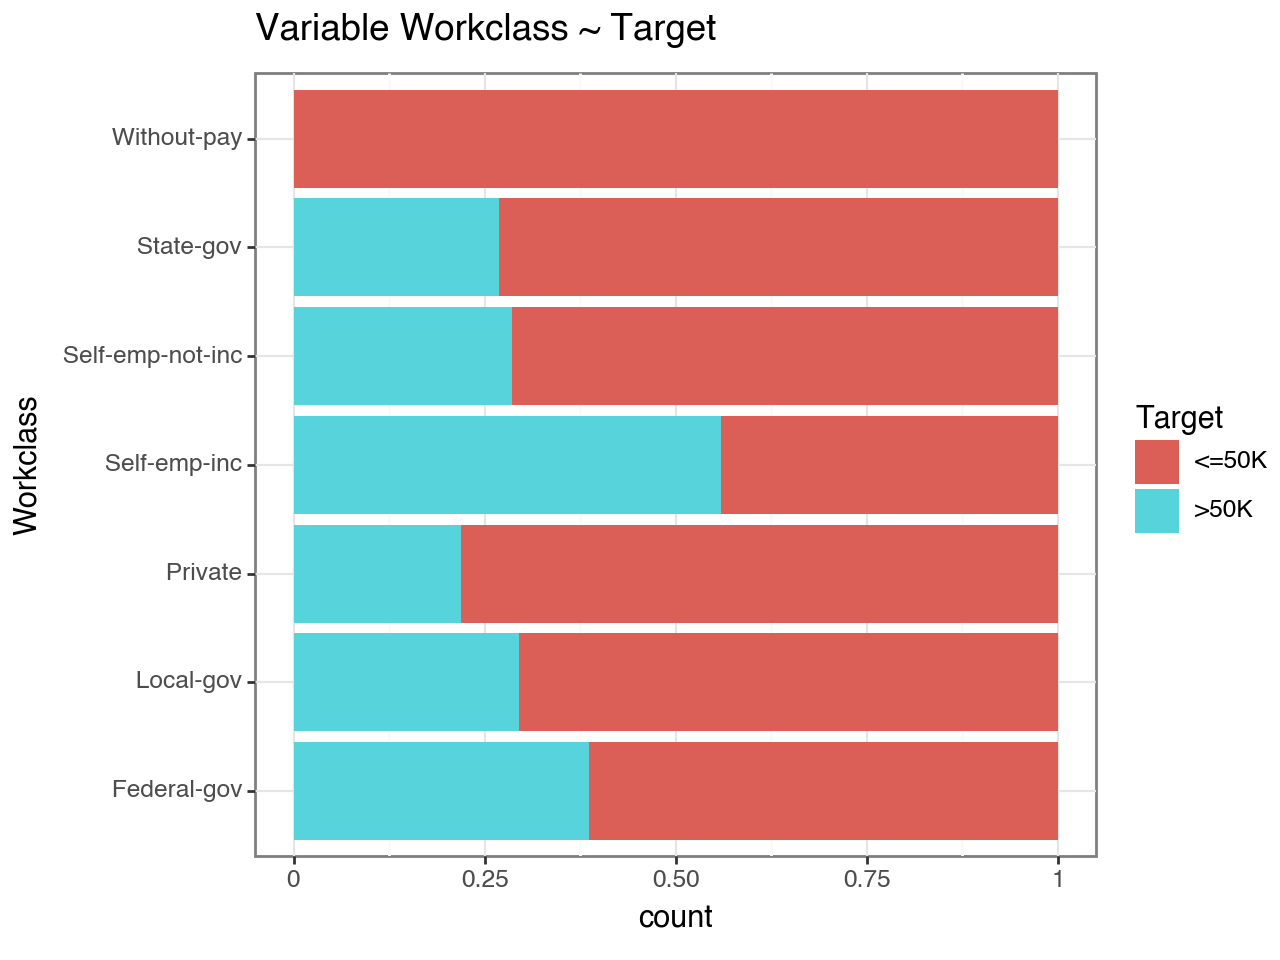

/Users/varunmallya/Documents/personal_projects/chapter-4/myvenv/lib/python3.9/site-packages/plotnine/ggplot.py:587: PlotnineWarning: Saving 6.4 x 4.8 in image.
/Users/varunmallya/Documents/personal_projects/chapter-4/myvenv/lib/python3.9/site-packages/plotnine/ggplot.py:588: PlotnineWarning: Filename: categorical_variable_plots/Variable Workclass


OSError: Project was not passed and could not be determined from the environment.

In [7]:


#Let´s see the distribution of our target variable - if the set is balanced. We´ll se it´s imbalanced.

print(df.Target.value_counts())

#Analysis of categorical data:
#mlflow the plots

with mlflow.start_run(run_name=f"eda-{uuid.uuid4()}"):
    for i in df.iloc[:,:-1].select_dtypes(include='object').columns:
        print(f'Variable {i}  \n ')
        print(df[i].value_counts())

        plot = ggplot(df)+ geom_bar(aes(x=df[i], fill=df.Target), position='fill')+ theme_bw() + labs(title=f'Variable {i} ~ Target')+ coord_flip()
        print(plot)
        if not os.path.exists("categorical_variable_plots"):
            os.makedirs("categorical_variable_plots")
        plot.save(f"categorical_variable_plots/Variable {i}")
        mlflow.log_artifacts("categorical_variable_plots")
    

In [7]:
#Separating the target

target=df.Target
feature_df=df.drop('Target', axis=1)


#Codifying the predictors and the target
encoder=OneHotEncoder(sparse=False, drop='if_binary')
target=encoder.fit_transform(np.array(target).reshape(-1,1))

#Dummifying



/Users/varunmallya/Documents/personal_projects/chapter-4/myvenv/lib/python3.9/site-packages/sklearn/preprocessing/_encoders.py:972: FutureWarning: `sparse` was renamed to `sparse_output` in version 1.2 and will be removed in 1.4. `sparse_output` is ignored unless you leave `sparse` to its default value.


In [8]:
feature_df.head()

,Workclass,Education,Marital-Status,Occupation,Relationship,Race,Sex,Native_country
0,State-gov,Bachelors,Never-married,Adm-clerical,Not-in-family,White,Male,United-States
1,Self-emp-not-inc,Bachelors,Married-civ-spouse,Exec-managerial,Husband,White,Male,United-States
2,Private,HS-grad,Divorced,Handlers-cleaners,Not-in-family,White,Male,United-States
3,Private,11th,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,United-States
4,Private,Bachelors,Married-civ-spouse,Prof-specialty,Wife,Black,Female,Cuba


In [79]:
dummyfied_df=pd.get_dummies(feature_df, drop_first=True, sparse=False, dtype=float)

In [80]:
col_list = dummyfied_df.columns.to_list()

In [111]:
len(dummyfied_df.columns.to_list())

90

In [42]:
mlflow.artifacts.download_artifacts("runs:/acbe18a831f14760a577098b91cbd318/column_list.pkl")

OSError: Project was not passed and could not be determined from the environment.

In [81]:
import pickle
with open('column_list.pkl', 'wb') as f:
     pickle.dump(col_list, f)

In [113]:
dummyfied_df.reindex(columns=col_list,fill_value=0)

,Workclass_ Local-gov,Workclass_ Private,Workclass_ Self-emp-inc,Workclass_ Self-emp-not-inc,Workclass_ State-gov,Workclass_ Without-pay,Education_ 11th,Education_ 12th,Education_ 1st-4th,Education_ 5th-6th,...,Native_country_ Portugal,Native_country_ Puerto-Rico,Native_country_ Scotland,Native_country_ South,Native_country_ Taiwan,Native_country_ Thailand,Native_country_ Trinadad&Tobago,Native_country_ United-States,Native_country_ Vietnam,Native_country_ Yugoslavia
0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30157,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
30158,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
30159,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
30160,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


In [26]:
run = mlflow.get_run("99bbc7b797154f1296dc2214de6a5c1b")

In [27]:
for dataset_input in run.inputs.dataset_inputs:
    for tag in dataset_input.tags:
        print(tag)
        if tag.value =="training":
            print(dataset_input.dataset.source)

<InputTag: key='mlflow.data.context', value='training'>
{"uri": "mlflow-datasets/income-classifier-datasets/train-f1aa82641d37432f8e78e5cc96cf76bc.csv"}
<InputTag: key='mlflow.data.context', value='testing'>
<InputTag: key='mlflow.data.context', value='reference_features'>


In [31]:
json.loads(dataset_input.dataset.source)["uri"]

'mlflow-datasets/income-classifier-datasets/test-7e23489cb236469a8a859204bdac410d.csv'

In [12]:
#Splitting in training and test

X_train,X_test,y_train, y_test=train_test_split(dummyfied_df.reindex(columns=col_list,fill_value=0)
, target, train_size=0.80, shuffle=True)

In [92]:
from evidently.metrics import ColumnDriftMetric
from evidently.metrics import ColumnSummaryMetric
from evidently.metrics import DatasetDriftMetric
from evidently.metrics import DatasetMissingValuesMetric
from evidently.report import Report

data_drift_report = Report(
    metrics=[
        DatasetDriftMetric(),
        DatasetMissingValuesMetric(),
        ColumnDriftMetric(column_name="Education", stattest="jensenshannon"),
        ColumnSummaryMetric(column_name="Education"),
        ColumnDriftMetric(column_name="Marital-Status", stattest="jensenshannon"),
        ColumnSummaryMetric(column_name="Marital-Status"),
        ColumnDriftMetric(column_name="Native_country", stattest="jensenshannon"),
        ColumnSummaryMetric(column_name="Native_country"),
        ColumnDriftMetric(column_name="Occupation", stattest="jensenshannon"),
        ColumnSummaryMetric(column_name="Occupation"),
        ColumnDriftMetric(column_name="Race", stattest="jensenshannon"),
        ColumnSummaryMetric(column_name="Race"),
        ColumnDriftMetric(column_name="Relationship", stattest="jensenshannon"),
        ColumnSummaryMetric(column_name="Relationship"),
        ColumnDriftMetric(column_name="Sex", stattest="jensenshannon"),
        ColumnSummaryMetric(column_name="Sex"),
        ColumnDriftMetric(column_name="Workclass", stattest="jensenshannon"),
        ColumnSummaryMetric(column_name="Workclass"),
    ],
)

In [93]:
df.head(100)

,Workclass,Education,Marital-Status,Occupation,Relationship,Race,Sex,Native_country,Target
0,State-gov,Bachelors,Never-married,Adm-clerical,Not-in-family,White,Male,United-States,<=50K
1,Self-emp-not-inc,Bachelors,Married-civ-spouse,Exec-managerial,Husband,White,Male,United-States,<=50K
2,Private,HS-grad,Divorced,Handlers-cleaners,Not-in-family,White,Male,United-States,<=50K
3,Private,11th,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,United-States,<=50K
4,Private,Bachelors,Married-civ-spouse,Prof-specialty,Wife,Black,Female,Cuba,<=50K
...,...,...,...,...,...,...,...,...,...
95,Private,Some-college,Never-married,Tech-support,Own-child,White,Female,United-States,<=50K
96,Private,HS-grad,Never-married,Craft-repair,Not-in-family,White,Male,United-States,<=50K
97,Self-emp-inc,HS-grad,Married-civ-spouse,Craft-repair,Husband,White,Male,United-States,>50K
98,Private,11th,Never-married,Handlers-cleaners,Own-child,White,Male,United-States,<=50K


In [99]:
data_drift_report.run(reference_data=df.drop(columns=["Target"]).head(100),current_data=df.drop(columns=["Target"]).tail(50))

/Users/varunmallya/Documents/personal_projects/chapter-4/myvenv/lib/python3.9/site-packages/scipy/stats/_stats_py.py:8064: RuntimeWarning: divide by zero encountered in divide
/Users/varunmallya/Documents/personal_projects/chapter-4/myvenv/lib/python3.9/site-packages/scipy/stats/_stats_py.py:8064: RuntimeWarning: divide by zero encountered in divide
/Users/varunmallya/Documents/personal_projects/chapter-4/myvenv/lib/python3.9/site-packages/scipy/stats/_stats_py.py:8064: RuntimeWarning: divide by zero encountered in divide
/Users/varunmallya/Documents/personal_projects/chapter-4/myvenv/lib/python3.9/site-packages/scipy/stats/_stats_py.py:8064: RuntimeWarning: divide by zero encountered in divide
/Users/varunmallya/Documents/personal_projects/chapter-4/myvenv/lib/python3.9/site-packages/scipy/stats/_stats_py.py:8064: RuntimeWarning: divide by zero encountered in divide
/Users/varunmallya/Documents/personal_projects/chapter-4/myvenv/lib/python3.9/site-packages/scipy/stats/_stats_py.py:806

In [98]:
df.drop(columns=["Target"]).tail(100).to_csv("drift_data.csv",index=False)

In [100]:
from evidently.ui.remote import RemoteWorkspace
ws = RemoteWorkspace("http://localhost:8004")
ws.add_report("8d82bd50-aa2d-4bb5-b258-964bf03f2665",data_drift_report)

In [60]:
from mlflow.tracking import MlflowClient
mlflow_host="http://mlflow.dev.jago.data:5000/"
mlflow_client = MlflowClient(mlflow_host)
model_name = "random-forest-classifier"
for model in mlflow_client.search_model_versions(f"name='{model_name}'"):
    if model.current_stage == "Staging":
        model_run_id = model.run_id

In [61]:
model_run_id

'c2cd3fd16c764a10b0c774bdd807e996'

In [70]:
import json
run = mlflow.get_run("67ec02dce22f4ab2a8881ac83cf13265")
for dataset_input in run.inputs.dataset_inputs:
    for tag in dataset_input.tags:
        print(tag)
        if tag.value == "reference_features":
            print(dataset_input)
            dataset_source = json.loads(dataset_input.dataset.source)["uri"]
            print(dataset_source)
            bucket_name = dataset_source.split("/")[0]

<InputTag: key='mlflow.data.context', value='training'>
<InputTag: key='mlflow.data.context', value='testing'>
<InputTag: key='mlflow.data.context', value='reference_features'>
<DatasetInput: dataset=<Dataset: digest='bef33769', name='dataset', profile='{"num_rows": 30162, "num_elements": 241296}', schema=('{"mlflow_colspec": [{"type": "string", "name": "Workclass"}, {"type": '
 '"string", "name": "Education"}, {"type": "string", "name": '
 '"Marital-Status"}, {"type": "string", "name": "Occupation"}, {"type": '
 '"string", "name": "Relationship"}, {"type": "string", "name": "Race"}, '
 '{"type": "string", "name": "Sex"}, {"type": "string", "name": '
 '"Native_country"}]}'), source=('{"uri": '
 '"mlflow-datasets/income-classifier-datasets/test-7e23489cb236469a8a859204bdac410d.csv"}'), source_type='local'>, tags=[<InputTag: key='mlflow.data.context', value='reference_features'>]>
mlflow-datasets/income-classifier-datasets/test-7e23489cb236469a8a859204bdac410d.csv


In [78]:
feature_df.columns

Index(['Workclass', 'Education', 'Marital-Status', 'Occupation',
       'Relationship', 'Race', 'Sex', 'Native_country'],
      dtype='object')

In [65]:
dataset_source

'mlflow-datasets/income-classifier-datasets/test-67ec02dce22f4ab2a8881ac83cf13265.csv'

In [25]:
x["metrics"][0]["result"]["share_of_drifted_columns"]

0.3333333333333333

In [13]:
from minio import Minio
minioClient = Minio("localhost:9000", access_key="minio", secret_key="minio123", secure=False)
found = minioClient.bucket_exists("mlflow-datasets")
print(found)


True


In [32]:

from io import BytesIO
def save_df_to_minio(df,bucket_name,path):
    csv_bytes = df.to_csv(index=False).encode('utf-8')
    csv_buffer = BytesIO(csv_bytes)

    minioClient.put_object(f'{bucket_name}',
                        f'{path}',
                            data=csv_buffer,
                            length=len(csv_bytes),
                            content_type='application/csv')

In [77]:
X_train.head(1)

,Workclass_ Local-gov,Workclass_ Private,Workclass_ Self-emp-inc,Workclass_ Self-emp-not-inc,Workclass_ State-gov,Workclass_ Without-pay,Education_ 11th,Education_ 12th,Education_ 1st-4th,Education_ 5th-6th,...,Native_country_ Portugal,Native_country_ Puerto-Rico,Native_country_ Scotland,Native_country_ South,Native_country_ Taiwan,Native_country_ Thailand,Native_country_ Trinadad&Tobago,Native_country_ United-States,Native_country_ Vietnam,Native_country_ Yugoslavia
25651,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


In [33]:
BUCKET_NAME = "mlflow-datasets"
with mlflow.start_run() as run:
    results=pd.DataFrame(index=['Roc Auc Score test', 'Accuracy score train', 'Accuracy Score test','time to fit'])
    tree=DecisionTreeClassifier()
    run_id = run.info.run_id
    feature_df_path = f"income-classifier-datasets/feature_df-{run_id}.csv"
    train_df = pd.concat([X_train,pd.Series(y_train.ravel())],axis=1)
    train_df_path = f"income-classifier-datasets/train-{run_id}.csv"
    save_df_to_minio(train_df,BUCKET_NAME,train_df_path)
    save_df_to_minio(feature_df,BUCKET_NAME,feature_df_path)
    test_df = pd.concat([X_test,pd.Series(y_test.ravel())],axis=1)
    test_df_path = f"income-classifier-datasets/test-{run_id}.csv"
    save_df_to_minio(test_df,BUCKET_NAME,test_df_path)
    #save dataframe to cloud provider
    training_dataset = mlflow.data.from_pandas(train_df, source=f"{BUCKET_NAME}/{train_df_path}")
    test_dataset = mlflow.data.from_pandas(test_df, source=f"{BUCKET_NAME}/{test_df_path}")
    feature_dataset = mlflow.data.from_pandas(feature_df, source=f"{BUCKET_NAME}/{feature_df_path}")
    mlflow.log_input(training_dataset,context="training")
    mlflow.log_input(test_dataset,context="testing")
    mlflow.log_input(feature_dataset,context="reference_features")
    tree.fit(X_train, y_train.ravel())
    roc_auc_score_train = roc_auc_score(y_train==1, tree.predict_proba(X_train)[:,1])
    roc_auc_score_test = roc_auc_score(y_test==1, tree.predict_proba(X_test)[:,1])
    training_accuracy = tree.score(X_train, y_train)
    test_accuracy = tree.score(X_test, y_test)
    mlflow.log_metric("roc_auc_score_train",roc_auc_score_train)
    print(f'Roc Auc Score train: {roc_auc_score_train}  \n')
    mlflow.log_metric("roc_auc_score_test",roc_auc_score_test)
    print(f'Roc Auc Score test: {roc_auc_score_test}  \n')
    mlflow.log_metric("training_accuracy",training_accuracy)
    print(f'Accuracy train : {training_accuracy}')
    mlflow.log_metric("test_accuracy",test_accuracy)
    print(f'Accuracy test : {test_accuracy}')
    mlflow.sklearn.log_model(tree,artifact_path="income-classifier")
    mlflow.log_params(tree.get_params())

ProtocolError: ('Connection aborted.', BadStatusLine('ÿ\x00\x00\x00\x00\x00\x00\x00\x01\x7f9\x017fb8.csv?uploads= HTTP/1.1\r\n'))

In [19]:
with mlflow.start_run():
    forest=RandomForestClassifier()

    start=time.time()
    train_df = pd.concat([X_train,pd.Series(y_train.ravel())],axis=1)
    test_df = pd.concat([X_test,pd.Series(y_test.ravel())],axis=1)
    feature_df_path = f"income-classifier-datasets/feature_df-{run_id}.csv"
    train_df_path = f"income-classifier-datasets/train-{run_id}.csv"
    save_df_to_minio(train_df,BUCKET_NAME,train_df_path)
    save_df_to_minio(feature_df,BUCKET_NAME,feature_df_path)
    test_df_path = f"income-classifier-datasets/test-{run_id}.csv"
    test_df_path = f"income-classifier-datasets/test-{run_id}.csv"
    save_df_to_minio(test_df,BUCKET_NAME,test_df_path)
    feature_dataset = mlflow.data.from_pandas(feature_df, source=f"{BUCKET_NAME}/{test_df_path}")
    training_dataset = mlflow.data.from_pandas(train_df, source=f"{BUCKET_NAME}/{train_df_path}")
    test_dataset = mlflow.data.from_pandas(test_df, source=f"{BUCKET_NAME}/{test_df_path}")
    mlflow.log_input(training_dataset,context="training")
    mlflow.log_input(test_dataset,context="testing")
    mlflow.log_input(feature_dataset,context="reference_features")
    forest.fit(X_train, y_train.ravel())
    end=time.time()

    roc_auc_score_train = roc_auc_score(y_train==1, forest.predict_proba(X_train)[:,1])
    roc_auc_score_test = roc_auc_score(y_test==1, forest.predict_proba(X_test)[:,1])
    training_accuracy = forest.score(X_train, y_train)
    test_accuracy = forest.score(X_test, y_test)

    mlflow.log_metric("roc_auc_score_train",roc_auc_score_train)
    print(f'Roc Auc Score train: {roc_auc_score_train}  \n')
    mlflow.log_metric("roc_auc_score_test",roc_auc_score_test)
    print(f'Roc Auc Score test: {roc_auc_score_test}  \n')
    mlflow.log_metric("training_accuracy",training_accuracy)
    print(f'Accuracy train : {training_accuracy}')
    mlflow.log_metric("test_accuracy",test_accuracy)
    print(f'Accuracy test : {test_accuracy}')
    mlflow.sklearn.log_model(forest,"income-classifier")
    
    mlflow.log_params(forest.get_params())

/Users/varunmallya/Documents/personal_projects/chapter-4/myvenv/lib/python3.9/site-packages/mlflow/data/dataset_source_registry.py:142: UserWarning: The specified dataset source can be interpreted in multiple ways: LocalArtifactDatasetSource, LocalArtifactDatasetSource. MLflow will assume that this is a LocalArtifactDatasetSource source.
/Users/varunmallya/Documents/personal_projects/chapter-4/myvenv/lib/python3.9/site-packages/mlflow/data/dataset_source_registry.py:142: UserWarning: The specified dataset source can be interpreted in multiple ways: LocalArtifactDatasetSource, LocalArtifactDatasetSource. MLflow will assume that this is a LocalArtifactDatasetSource source.


Roc Auc Score train: 0.9282140293896523  

Roc Auc Score test: 0.8617613249257084  

Accuracy train : 0.8641883211073812
Accuracy test : 0.8198242996850654


In [18]:
#Let´s train the model


with mlflow.start_run():
    mlflow.xgboost.autolog()
    n_round=30
    dtrain= xgb.DMatrix(data=X_train, label=y_train.ravel())
    dtest= xgb.DMatrix(data=X_test, label=y_test.ravel())
    params={"objective":"binary:logistic",'colsample_bytree': 1,'learning_rate': 1,
                    'max_depth': 10 , 'subsample':1}
    model=xgb.train(params,dtrain, n_round)
    ax = xgb.plot_importance(model, max_num_features=10, importance_type='cover')
    fig = ax.figure
    fig.set_size_inches(10, 8)
    pred_train= model.predict(dtrain)
    pred_test=model.predict(dtest)
    model=xgb.train(params={"objective":"binary:hinge",'colsample_bytree': 1,'learning_rate': 1,
                    'max_depth': 10 , 'subsample':1}, dtrain=dtrain)
    pred_train= model.predict(dtrain)
    pred_test=model.predict(dtest)


    roc_auc_score_train = roc_auc_score(y_train==1, pred_train)
    roc_auc_score_test = roc_auc_score(y_test==1, pred_test)
    training_accuracy = accuracy_score(y_train, pred_train)
    test_accuracy = accuracy_score(y_test, pred_test)

    mlflow.log_metric("roc_auc_score_train",roc_auc_score_train)
    print(f'Roc Auc Score train: {roc_auc_score_train}  \n')
    mlflow.log_metric("roc_auc_score_test",roc_auc_score_test)
    print(f'Roc Auc Score test: {roc_auc_score_test}  \n')
    mlflow.log_metric("training_accuracy",training_accuracy)
    print(f'Accuracy train : {training_accuracy}')
    mlflow.log_metric("test_accuracy",test_accuracy)
    print(f'Accuracy test : {test_accuracy}')

2023/10/08 12:01:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during xgboost autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID d24b13ea9abb4885ba370b160c4e22a0. Failed operations: [MlflowException("API request to http://localhost:5000/api/2.0/mlflow/runs/log-batch failed with exception HTTPConnectionPool(host=\'localhost\', port=5000): Max retries exceeded with url: /api/2.0/mlflow/runs/log-batch (Caused by ResponseError(\'too many 500 error responses\'))")]')]


Roc Auc Score train: 0.7615672975468365  

Roc Auc Score test: 0.720134159599913  

Accuracy train : 0.8484396369513862
Accuracy test : 0.8170064644455495


In [20]:
from mlflow import MlflowClient

mlflow_client = MlflowClient()
experiment_name = "income-classifier"
experiment = mlflow_client.get_experiment_by_name(experiment_name)
run_object = mlflow_client.search_runs(experiment_ids=experiment.experiment_id,filter_string="metrics.roc_auc_score_test > 0.8",max_results=1,order_by=["metrics.roc_auc_score_test DESC"])[0]
model_uri = f"runs:/{run_object.info.run_id}/{experiment_name}"
mlflow.register_model(model_uri, "random-forest-classifier")




Successfully registered model 'random-forest-classifier'.
2023/10/08 12:57:19 INFO mlflow.tracking._model_registry.client: Waiting up to 300 seconds for model version to finish creation. Model name: random-forest-classifier, version 1
Created version '1' of model 'random-forest-classifier'.


<ModelVersion: aliases=[], creation_timestamp=1696741039791, current_stage='None', description='', last_updated_timestamp=1696741039791, name='random-forest-classifier', run_id='d853c533ddbd47a09d82d83f6acba58f', run_link='', source='mlflow-artifacts:/754759727085360337/d853c533ddbd47a09d82d83f6acba58f/artifacts/income-classifier', status='READY', status_message='', tags={}, user_id='', version='1'>

In [68]:
import mlflow

In [69]:
mlflow.set_tracking_uri("http://mlflow.prod.jago.data:5000/")
mlflow.set_experiment("sfs-bscore-model-development")

<Experiment: artifact_location='gs://mlflow_artifacts_production/35', creation_time=None, experiment_id='35', last_update_time=None, lifecycle_stage='active', name='sfs-bscore-model-development', tags={}>

In [70]:
with mlflow.start_run():
    print("empty run")

empty run
